## API 키 설정 

In [1]:
# Load environment variables in a file called .env
# API 키 설정 
import os
from dotenv import load_dotenv

load_dotenv(override=True)
api_key = os.getenv('OPENAI_API_KEY')
google_api_key = os.getenv('GOOGLE_API_KEY')

# Check the key
if not api_key:
    print("No API key was found - please head over to the troubleshooting notebook in this folder to identify & fix!")
elif not api_key.startswith("sk-proj-"):
    print("An API key was found, but it doesn't start sk-proj-; please check you're using the right key - see troubleshooting notebook")
elif api_key.strip() != api_key:
    print("An API key was found, but it looks like it might have space or tab characters at the start or end - please remove them - see troubleshooting notebook")
else:
    print("API key found and looks good so far!")

if google_api_key:
    print(f"Google API Key exists and begins {google_api_key[:2]}")
else:
    print("Google API Key not set (and this is optional)")

API key found and looks good so far!
Google API Key exists and begins AI


## LCEL

In [17]:
from langchain_core.prompts import PromptTemplate
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

# -------------------------------------------------------
# 방법 1: PromptTemplate (단순 문자열 템플릿)
# -------------------------------------------------------
# PromptTemplate은 단순 문자열 형태의 프롬프트를 만들 때 사용합니다.
# {language}, {text} 자리에 사용자가 입력한 값이 채워집니다.
# 주의: 이 아래에서 ChatPromptTemplate으로 덮어쓰므로 실제로는 사용되지 않습니다.
template = """
다음 문장을 {language}로 번역해.
---
{text}
"""

prompt_template = PromptTemplate(
    input_variables=["language", "text"],  # 외부에서 입력받을 변수 목록
    template=template                       # 위에서 정의한 문자열 템플릿
)

# -------------------------------------------------------
# 방법 2: ChatPromptTemplate (대화형 템플릿) ← 실제 사용
# -------------------------------------------------------
# ChatPromptTemplate은 system/human/ai 역할을 구분하여
# 대화 형식으로 프롬프트를 구성할 때 사용합니다.
# from_messages()에 (역할, 내용) 튜플 리스트를 전달합니다.
#
# - "system": LLM의 행동 방식을 지시하는 시스템 메시지
#             {language} 자리에 번역할 언어가 채워집니다.
# - "human" : 사용자가 입력하는 메시지
#             {text} 자리에 번역할 원문이 채워집니다.
#
# 위의 PromptTemplate을 덮어씁니다.
prompt_template = ChatPromptTemplate.from_messages(
    [
        ("system", "사용자가 입력한 문장을 {language}로 번역해."),
        ("human", "{text}")
    ]
)

# ChatOpenAI 모델을 초기화합니다.
# gpt-4o-mini: 빠르고 경제적인 GPT-4o 경량 모델입니다.
llm = ChatOpenAI(model="gpt-4o-mini")

# StrOutputParser를 초기화합니다.
# LLM이 반환하는 AIMessage 객체에서 텍스트(.content)만 추출합니다.
# 예: AIMessage(content="Today I should eat pizza!") → "Today I should eat pizza!"
parser = StrOutputParser()

# LCEL 파이프라인으로 체인을 구성합니다.
# 실행 순서: prompt_template → llm → parser
# 1. prompt_template : {language}, {text} 변수를 채워 메시지 리스트 생성
# 2. llm             : 메시지를 받아 번역된 텍스트를 AIMessage로 반환
# 3. parser          : AIMessage에서 순수 텍스트만 추출
chain = prompt_template | llm | parser

# 체인을 실행합니다.
# invoke()에 딕셔너리로 변수를 전달합니다.
# - language: 번역할 대상 언어
# - text    : 번역할 원본 문장
response = chain.invoke(
    {
        "language": "영어",
        "text": "오늘은 피자를 먹어야지!"
    }
)

# 번역 결과를 출력합니다.
# 예상 출력: "Today I should eat pizza!"
print(response)

Today, I will eat pizza!


In [18]:
chain.invoke(
    {
        "language": "영어",
        "text": "내일은 수영을 가야지!"
    }
)

'I will go swimming tomorrow!'

LCEL 없이 작성

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

# ChatPromptTemplate으로 대화형 프롬프트 템플릿을 정의합니다.
# - "system": LLM의 역할과 행동 방식을 지시합니다.
# - "human" : 사용자가 입력하는 메시지입니다.
prompt_template = ChatPromptTemplate.from_messages(
    [
        ("system", "사용자가 입력한 문장을 {language}로 번역해."),
        ("human", "{text}")
    ]
)

# ChatOpenAI 모델을 초기화합니다.
llm = ChatOpenAI(model="gpt-4o-mini")

# StrOutputParser를 초기화합니다.
# AIMessage 객체에서 텍스트(.content)만 추출합니다.
parser = StrOutputParser()

# 1단계: 프롬프트 생성
# format_messages()로 변수를 채워 메시지 리스트를 생성합니다.
messages = prompt_template.format_messages(
    language="영어",
    text="오늘은 피자를 먹어야지!"
)

# 2단계: LLM 호출
# invoke()로 메시지를 전달하여 AIMessage 객체를 반환받습니다.
output = llm.invoke(messages)

# 3단계: 파싱
# AIMessage 객체에서 텍스트만 추출합니다.
response = parser.invoke(output)

# 번역 결과를 출력합니다.
# 예상 출력: "Today I should eat pizza!"
print(response)

# LCEL(LangChain Expression Language)




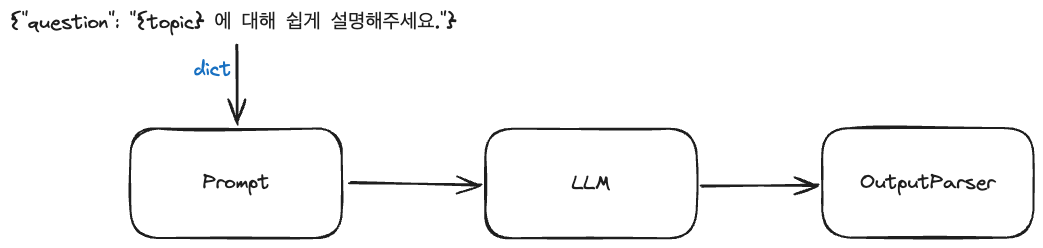

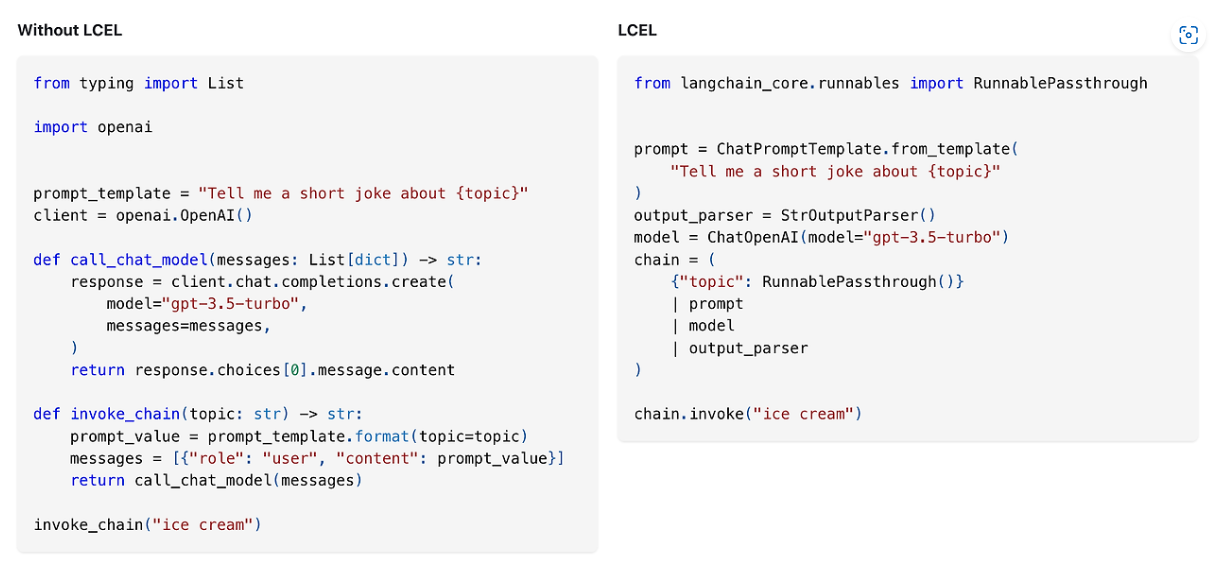

Component들을 연결할(chaining)때 사용함


# 일반적인 LCEL

In [9]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

# prompt 를 PromptTemplate 객체로 생성합니다.
prompt = PromptTemplate.from_template("{topic} 에 대해 쉽게 설명해주세요.")

model = ChatOpenAI(model_name='gpt-4.1-nano')

output_parser =StrOutputParser()

chain = prompt | model | output_parser
chain.invoke({"topic": "생성형AI"})

'물론이죠! 생성형 AI는 "새로운 콘텐츠를 만들어내는 인공지능"을 말해요. 예를 들어, 글을 쓰거나 그림을 그리거나 음악을 작곡하는 것처럼 사람이 하는 창작 활동을 AI가 대신 하는 것이에요.\n\n쉽게 비유하자면, 생성형 AI는 많은 데이터를 보고 배운 뒤, 새로운 아이디어나 내용을 만들어내는 만능 창작자라고 할 수 있어요. 예를 들어, "이야기를 써줘"라고 하면 새로운 이야기를 만들어내거나, "이 그림을 그려줘"라고 요청하면 그림을 만들어 내는 식이죠.\n\n이 기술은 챗GPT처럼 대화도 할 수 있고, 이미지 생성 AI도 있어요. 이렇게 여러 방면에서 우리 생활을 더 편리하게 만들어주는 역할을 하고 있답니다.'

LCEL2

In [10]:
from langchain_core.runnables import RunnablePassthrough
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_template(
    "{topic}에 대해 설명해주세요"
)
model = ChatOpenAI(model_name='gpt-4.1-nano')

output_parser = StrOutputParser()

chain = (
    {"topic": RunnablePassthrough()}
    | prompt
    | model
    | output_parser
)

chain.invoke("ice cream")


'아이스크림은 차갑고 달콤한 디저트로, 주로 우유, 크림, 설탕 등을 기본 재료로 하여 만들어집니다. 다양한 맛과 향을 넣어 즐기며, 아이스크림 콘이나 컵에 담아 먹거나, 다양한 디저트와 함께 제공되기도 합니다. 아이스크림은 냉동 과정을 거쳐서 부드럽고 쫄깃한 식감을 가지며, 여름철에 특히 인기가 많습니다. 또한, 바닐라, 초콜릿, 딸기, 민트와 초콜릿 칩 등 많은 맛 종류가 있으며, 아이스크림은 글로벌한 간식이자 즐거움의 상징으로 사랑받고 있습니다.'

# 프롬프트 prompt + 언어모델 model + 출력파서 output parser

In [11]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# prompt + model + output parser
prompt = ChatPromptTemplate.from_template("You are an expert in astronomy. Answer the question. : {input}")

llm = ChatOpenAI(model_name='gpt-4.1-nano')

output_parser = StrOutputParser()

# LCEL chaining
chain = prompt | llm | output_parser

# chain 호출
chain.invoke({"input": "지구의 자전 주기는?"})

'지구의 자전 주기는 약 24시간, 즉 하루입니다. 정확히는 평균 약 23시간 56분 4초(즉, 약 23.9345시간)로, 이를 항성일(sidereal day)이라고 합니다. 하지만 일상 생활에서는 태양이 같은 위치에 다시 도달하는 하루, 즉 태양일(solar day)이 약 24시간으로 간주됩니다.'

# 고급(Multiple chain)

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
llm = ChatOpenAI(model_name='gpt-4.1-nano')

prompt1 = ChatPromptTemplate.from_template("아래 단어와 관련해서 30자 시나리오를 써라 {korean_word}")


chain1 = prompt1 | llm | StrOutputParser()

chain1.invoke({"korean_word":"미래"})

'미래를 향해 달려가는 시간 속, 희망의 빛이 피어난다.'

In [14]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
llm = ChatOpenAI(model_name='gpt-4.1-nano')

prompt2 = ChatPromptTemplate.from_template(
    "아래 내용에서 주요 키워드3개를 추출하라 {english_word}"
)


chain2 = (
    {"english_word": chain1}
    | prompt2
    | llm
    | StrOutputParser()
)

chain2.invoke({"korean_word":"미래"})

'1. 미래  \n2. 꿈  \n3. 희망'

PromptTemplate & LCEL

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

# 첫 번째 프롬프트 템플릿을 정의합니다.
# {sentence} 자리에 사용자가 입력한 문장이 들어갑니다.
# LLM에게 입력된 문장을 5자 이내로 요약하도록 지시합니다.
prompt1 = PromptTemplate.from_template("다음 문장을 5자내로 요약하세요\n\n{sentence}")

# 두 번째 프롬프트 템플릿을 정의합니다.
# {summary} 자리에 첫 번째 체인의 요약 결과가 들어갑니다.
# LLM에게 요약된 문장을 영어로 번역하도록 지시합니다.
prompt2 = PromptTemplate.from_template("다음 문장을 영어로 번역하세요.\n\n{summary}")

# ChatOpenAI 모델을 초기화합니다.
model = ChatOpenAI(model_name='gpt-4.1-nano')

# StrOutputParser를 초기화합니다.
# LLM이 반환하는 AIMessage 객체에서 텍스트(.content)만 추출해줍니다.
# 예: AIMessage(content="AI 맞춤") → "AI 맞춤"
output_parser = StrOutputParser()

# 첫 번째 LCEL 체인을 구성합니다. (요약 체인)
# prompt1 → model → output_parser 순서로 실행됩니다.
# 1. prompt1: {sentence}를 채워 프롬프트 문자열 생성
# 2. model: 프롬프트를 받아 요약된 텍스트 생성
# 3. output_parser: AIMessage에서 텍스트만 추출
chain1 = prompt1 | model | output_parser

# 두 번째 LCEL 체인을 구성합니다. (번역 체인)
# prompt2 → model → output_parser 순서로 실행됩니다.
# 1. prompt2: {summary}를 채워 프롬프트 문자열 생성
# 2. model: 프롬프트를 받아 번역된 텍스트 생성
# 3. output_parser: AIMessage에서 텍스트만 추출
chain2 = prompt2 | model | output_parser

# 두 체인을 순차적으로 실행하는 함수를 정의합니다.
# sentence: 요약 및 번역할 원본 문장
# 반환값: {"summary": 요약 결과, "translation": 번역 결과} 딕셔너리
def combined_chain(sentence):
    # chain1을 실행하여 문장을 요약합니다.
    # {"sentence": sentence}로 프롬프트의 {sentence} 변수를 채웁니다.
    # 결과: 5자 이내로 요약된 문자열
    summary = chain1.invoke({"sentence": sentence})

    # chain2를 실행하여 요약된 문장을 영어로 번역합니다.
    # {"summary": summary}로 프롬프트의 {summary} 변수를 채웁니다.
    # 결과: 영어로 번역된 문자열
    translation = chain2.invoke({"summary": summary})

    # 요약과 번역 결과를 딕셔너리로 반환합니다.
    return {"summary": summary, "translation": translation}

# 요약 및 번역할 원본 문장을 정의합니다.
sentence = "기존 LLM의 한계를 극복하기 위해 맞춤형 AI들이 개발되고 있는데요..."

# combined_chain 함수를 호출하여 요약과 번역을 순차적으로 실행합니다.
result = combined_chain(sentence)

# 최종 결과를 출력합니다.
# 예: {"summary": "AI 맞춤 개발", "translation": "Custom AI development"}
print(result)

{'summary': '맞춤 AI 개발', 'translation': 'Customized AI Development'}
